---
title: "Lecture 17: Orthogonal iteration and QR iteration"
author: "Jamie Haddock"
format: 
    revealjs:
        output-file: Lecture17_slides
        slide-number: true
        preview-links: auto
        logo: figs/hmc.png
        css: input/slides.css
        incremental: true
        smaller: true
        code-fold: true
        embed-resources: true
        html-math-method: mathjax
    html: 
        output-file: Lecture17
        code-fold: true
        embed-resources: true
        code-links:
        - text: "Open in Colab"
          href: "https://colab.research.google.com/github/jamiehadd/Math-189M-NumericalLinearAlgebra/blob/main/Lecture17_Orthogonal_QR_iteration.ipynb"
          icon: "laptop"
    pdf:
        output-file: Lecture17
        documentclass: article
        toc: true
        number-sections: true
        geometry:
          - top=1in
          - left=1in
          - bottom=1in
          - right=1in
format-links: false
jupyter: julia-1.9
colab:
  gh-user: "jamiehadd"   
  gh-repo: "Math-189M-NumericalLinearAlgebra" 
filters: 
  - input/remove-pause.lua
  - colab
execute:
  echo: true
  eval: true
---

# Orthogonal iteration and QR iteration

Power iteration finds just one eigenpair at a time, and only the dominant one. Can we find *several* eigenvalues at once, or even all of them? In this lecture we run power iteration on a whole block of vectors simultaneously, and add one extra ingredient, orthogonalization, to keep the vectors from all collapsing onto the same dominant eigenvector. The result is the **QR iteration**, which (with some important improvements) is the basis of the standard algorithm for computing all the eigenvalues of a matrix.

. . .

::: {.callout-note icon=false}
## Assumption:
Throughout this lecture, we assume that $\mathbf{A}$ is a diagonalizable $n\times n$ matrix whose eigenvalues satisfy
$$|\lambda_1| > |\lambda_2| > \cdots > |\lambda_n|.$$
We write $\mathbf{A}=\mathbf{V}\mathbf{D}\mathbf{V}^{-1}$, where $\mathbf{V}=\begin{bmatrix}\mathbf{v}_1 & \cdots & \mathbf{v}_n\end{bmatrix}$ holds the eigenvectors and $\mathbf{D}=\operatorname{diag}(\lambda_1,\ldots,\lambda_n)$.
:::

[For a real matrix $\mathbf{A}$ this assumption forces every eigenvalue to be real, since complex eigenvalues come in conjugate pairs and conjugates have equal modulus. So all of the computations below can be done in real arithmetic, with real orthogonal matrices in place of unitary ones and $\mathbf{Q}^*=\mathbf{Q}^\top$.]{.content-hidden when-format='revealjs' when-format='pptx'}

## Schur decomposition

Power iteration produces an *eigenvector*. The natural target of the algorithms in this lecture is a different object, one that exists for every square matrix and is much better behaved numerically than the eigenvector matrix $\mathbf{V}$.

. . .

::: {.callout-note icon=false}
## Definition: Schur decomposition
A **Schur decomposition** of an $n\times n$ matrix $\mathbf{A}$ is a factorization
$$\mathbf{A} = \mathbf{Q}\mathbf{T}\mathbf{Q}^*,$$
where $\mathbf{Q}$ is unitary ($\mathbf{Q}^*\mathbf{Q}=\mathbf{I}$) and $\mathbf{T}$ is upper triangular. The columns of $\mathbf{Q}$ are called **Schur vectors**.
:::

. . .

Compare this with the eigendecomposition $\mathbf{A}=\mathbf{V}\mathbf{D}\mathbf{V}^{-1}$. We have traded a *diagonal* matrix for a merely *triangular* one, but in return $\mathbf{Q}$ has orthonormal columns (so $\kappa_2(\mathbf{Q})=1$), whereas $\mathbf{V}$ can be badly conditioned, or fail to exist at all if $\mathbf{A}$ is not diagonalizable.

---

::: {.callout-warning icon=false}
## Theorem:
Let $\mathbf{A}$ be an $n\times n$ matrix.

1. $\mathbf{A}$ has a Schur decomposition $\mathbf{A}=\mathbf{Q}\mathbf{T}\mathbf{Q}^*$.
2. The diagonal entries of $\mathbf{T}$ are the eigenvalues of $\mathbf{A}$.
3. For each $j=1,\ldots,n$, let $\mathbf{Q}_j$ be the first $j$ columns of $\mathbf{Q}$ and $\mathbf{T}_j$ the leading $j\times j$ block of $\mathbf{T}$. Then $\mathbf{A}\mathbf{Q}_j=\mathbf{Q}_j\mathbf{T}_j$. That is, $\operatorname{range}(\mathbf{Q}_j)$ is an *invariant subspace* of $\mathbf{A}$: $\mathbf{x}\in\operatorname{range}(\mathbf{Q}_j)$ implies $\mathbf{A}\mathbf{x}\in\operatorname{range}(\mathbf{Q}_j)$.
:::

<details><summary>Proof sketch:</summary>

For part 1 we use induction on $n$, and assume a matrix of size $n-1 \times n-1$ has a Schur decomposition. 

Let $(\lambda,\mathbf{v})$ be an eigenpair of $\mathbf{A}$ with $\|\mathbf{v}\|_2=1$ (one exists over $\mathbb{C}$), and extend $\mathbf{v}$ to a unitary matrix $\mathbf{U}=\begin{bmatrix}\mathbf{v} & \mathbf{U}_2\end{bmatrix}$. Because $\mathbf{U}^*\mathbf{A}\mathbf{v}=\lambda\mathbf{U}^*\mathbf{v}=\lambda\mathbf{e}_1$,

$$\mathbf{U}^*\mathbf{A}\mathbf{U}=\begin{bmatrix}\lambda & \mathbf{w}^*\\ \mathbf{0} & \mathbf{A}_2\end{bmatrix}$$

for some vector $\mathbf{w}$ and some $(n-1)\times(n-1)$ matrix $\mathbf{A}_2$. By induction, $\mathbf{A}_2=\mathbf{Q}_2\mathbf{T}_2\mathbf{Q}_2^*$ with $\mathbf{Q}_2$ unitary and $\mathbf{T}_2$ upper triangular. Setting $\mathbf{Q}=\mathbf{U}\begin{bmatrix}1&\\&\mathbf{Q}_2\end{bmatrix}$ (a product of unitary matrices),

$$\mathbf{Q}^*\mathbf{A}\mathbf{Q}=\begin{bmatrix}\lambda & \mathbf{w}^*\mathbf{Q}_2\\ \mathbf{0} & \mathbf{T}_2\end{bmatrix},$$

which is upper triangular.

For part 2, $\mathbf{T}=\mathbf{Q}^*\mathbf{A}\mathbf{Q}$ is similar to $\mathbf{A}$, so it has the same eigenvalues, and the eigenvalues of a triangular matrix are its diagonal entries.

For part 3, take the first $j$ columns of $\mathbf{A}\mathbf{Q}=\mathbf{Q}\mathbf{T}$. Since $\mathbf{T}$ is upper triangular, its first $j$ columns are zero below row $j$, so the right-hand side is $\mathbf{Q}_j\mathbf{T}_j$.
</details>

---

Reading $\mathbf{A}\mathbf{Q}=\mathbf{Q}\mathbf{T}$ one column at a time,

$$\begin{split}
\mathbf{A}\mathbf{q}_1 &= t_{11}\mathbf{q}_1,\\
\mathbf{A}\mathbf{q}_2 &= t_{12}\mathbf{q}_1 + t_{22}\mathbf{q}_2,\\
&\;\;\vdots\\
\mathbf{A}\mathbf{q}_j &= t_{1j}\mathbf{q}_1 + \cdots + t_{jj}\mathbf{q}_j.
\end{split}$$

. . .

So the first Schur vector $\mathbf{q}_1$ is an eigenvector of $\mathbf{A}$, with eigenvalue $t_{11}$. The later Schur vectors are **not** eigenvectors in general: $\mathbf{q}_j$ is an eigenvector only "modulo" $\mathbf{q}_1,\ldots,\mathbf{q}_{j-1}$. But the eigenvalues all sit on the diagonal of $\mathbf{T}$, and that is what we need in order to compute them.

. . .

**Goal:** compute a Schur decomposition (or just its first few columns), using only matrix products and orthogonalization.

## Orthogonal iteration

Power iteration applied to a vector $\mathbf{x}$ converges to the direction of $\mathbf{v}_1$, which is also the first Schur vector $\mathbf{q}_1$. How could we find the *second* Schur vector as well?

. . .

**Idea:** run power iteration on *two* vectors $\mathbf{x}$ and $\mathbf{y}$ at once. Unfortunately, if we just compute $\mathbf{A}^k\mathbf{x}$ and $\mathbf{A}^k\mathbf{y}$, then both converge to the direction of $\mathbf{v}_1$ (generically, both have a nonzero component along $\mathbf{v}_1$). We learn nothing about $\mathbf{q}_2$, and the two vectors become nearly parallel, a poor (nearly dependent) basis for the plane they span.

---

**Fix:** what *does* converge is the two-dimensional *span* of $\mathbf{A}^k\mathbf{x}$ and $\mathbf{A}^k\mathbf{y}$. It is drawn toward $\operatorname{span}\{\mathbf{v}_1,\mathbf{v}_2\}$, the invariant subspace belonging to the two dominant eigenvalues. So at every step we replace the pair of vectors by an **orthonormal basis** for the same span. Starting from $\begin{bmatrix}\mathbf{q}_1 & \mathbf{q}_2\end{bmatrix}$ with orthonormal columns, one step is

$$\mathbf{A}\begin{bmatrix}\mathbf{q}_1 & \mathbf{q}_2\end{bmatrix} = \begin{bmatrix}\mathbf{q}_1^{+} & \mathbf{q}_2^{+}\end{bmatrix}\begin{bmatrix}r_{11} & r_{12}\\ 0 & r_{22}\end{bmatrix}\qquad\text{(a reduced QR factorization).}$$

. . .

Reading this column by column,

$$\mathbf{q}_1^+ = \frac{\mathbf{A}\mathbf{q}_1}{r_{11}},\qquad \mathbf{q}_2^+ = \frac{\mathbf{A}\mathbf{q}_2 - r_{12}\mathbf{q}_1^+}{r_{22}}.$$

The first vector is just a normalized power iteration. The second is $\mathbf{A}\mathbf{q}_2$ with its component along $\mathbf{q}_1^+$ removed, then normalized (Gram–Schmidt!). The two vectors cannot collapse onto each other, since $\mathbf{q}_2^+\perp\mathbf{q}_1^+$ by construction.

---

Where does this lead? Suppose $\mathbf{q}_1$ converges to an eigenvector and $\operatorname{span}\{\mathbf{q}_1,\mathbf{q}_2\}$ converges to $\operatorname{span}\{\mathbf{v}_1,\mathbf{v}_2\}$. Then in the limit

$$\mathbf{A}\mathbf{q}_1 = t_{11}\mathbf{q}_1,\qquad \mathbf{A}\mathbf{q}_2 = t_{12}\mathbf{q}_1 + t_{22}\mathbf{q}_2,$$

since $\mathbf{A}\mathbf{q}_2\in\operatorname{span}\{\mathbf{v}_1,\mathbf{v}_2\}=\operatorname{span}\{\mathbf{q}_1,\mathbf{q}_2\}$. These are exactly the first two columns of a Schur decomposition!

. . .

Notice that $\mathbf{q}_2$ is a unit vector in $\operatorname{span}\{\mathbf{v}_1,\mathbf{v}_2\}$ that is orthogonal to $\mathbf{v}_1$. In general it is *not* $\mathbf{v}_2$.

---

The same idea works for any number $r\le n$ of vectors.

**Algorithm: Orthogonal iteration**

Given matrix $\mathbf{A}$ and a number of columns $r$:

1. Choose $\mathbf{Q}_0\in\mathbb{R}^{n\times r}$ with orthonormal columns (for instance, the $\mathbf{Q}$ factor of a random matrix).

2. For $k=1,2,\ldots$,

    a. Set $\mathbf{Z}_k = \mathbf{A}\mathbf{Q}_{k-1}$.

    b. Find a reduced QR factorization $\mathbf{Z}_k=\mathbf{Q}_k\mathbf{R}_k$, where $\mathbf{Q}_k$ is $n\times r$ with orthonormal columns and $\mathbf{R}_k$ is $r\times r$ upper triangular.

<br><br>

. . .

After each iteration, the $r\times r$ matrix $\mathbf{T}_k=\mathbf{Q}_k^*\mathbf{A}\mathbf{Q}_k$ provides eigenvalue estimates on its diagonal. For $r=1$, this is exactly the power iteration (normalizing with the 2-norm instead of the $\infty$-norm).

---

Since a product of upper triangular matrices is upper triangular, the iteration satisfies

$$\mathbf{A}^k\mathbf{Q}_0 = \mathbf{Q}_k\,\underbrace{\mathbf{R}_k\mathbf{R}_{k-1}\cdots\mathbf{R}_1}_{\text{upper triangular}}.$$

[(By induction: $\mathbf{A}^k\mathbf{Q}_0=\mathbf{A}\mathbf{Q}_{k-1}(\mathbf{R}_{k-1}\cdots\mathbf{R}_1)=\mathbf{Q}_k\mathbf{R}_k\mathbf{R}_{k-1}\cdots\mathbf{R}_1$.)]{.content-hidden when-format='revealjs' when-format='pptx'}

. . .

In other words, for each $j\le r$ the first $j$ columns of $\mathbf{Q}_k$ are an orthonormal basis for the range of the first $j$ columns of $\mathbf{A}^k\mathbf{Q}_0$. **Orthogonal iteration is power iteration on subspaces**, and the QR factorization is a stable way to keep track of a basis for them.

In [1]:
# | echo: false
using LinearAlgebra
using Plots

In [2]:
"""
    orthiter(A,r,numiter)

Perform `numiter` orthogonal iterations with the matrix `A`, tracking `r`
columns and starting from a random matrix with orthonormal columns. Returns an
`r×numiter` matrix whose `k`th column is the diagonal of `Q_k'*A*Q_k` (the
eigenvalue estimates after `k` iterations), and the final `n×r` matrix `Q`.
"""
function orthiter(A,r,numiter)
    n = size(A,1)
    Q = Matrix(qr(randn(n,r)).Q)     # n×r matrix with orthonormal columns
    d = zeros(r,numiter)
    for k in 1:numiter
        Z = A*Q
        Q = Matrix(qr(Z).Q)          # reduced QR: keep the n×r factor Q
        d[:,k] = diag(Q'*Z)          # diagonal of Q_k'*A*Q_k
    end
    return d,Q
end

orthiter (generic function with 1 method)

. . .

As in the power iteration, the only use of $\mathbf{A}$ is to compute the product $\mathbf{A}\mathbf{Q}$, which easily exploits the sparsity of $\mathbf{A}$.

---

### Convergence to the Schur decomposition

::: {.callout-warning icon=false}
## Punchline:
Let $\mathbf{A} = \mathbf{V}\mathbf{D}\mathbf{V}^{-1}$, and let $1\le r\le n$. Define $\mathbf{Q}^{\mathbf{V}}$ to be the $n \times r$ matrix produced by the QR decomposition of the matrix whose columns are the eigenvectors associated to the top $r$ eigenvalues.  The matrix $\mathbf{Q}_k^\top \mathbf{A} \mathbf{Q}_k$ converges (up to some sign changes) to $$[\mathbf{Q}^{\mathbf{V}}]^\top \mathbf{A} \mathbf{Q}^{\mathbf{V}}$$ which is upper-triangular and has the top $r$ eigenvalues $\lambda_1, \cdots, \lambda_r$ of $\mathbf{A}$ on the diagonal.
:::



---

Let's test this on a $5\times5$ matrix with prescribed eigenvalues, built as $\mathbf{A}=\mathbf{V}\mathbf{D}\mathbf{V}^{-1}$ from a random matrix $\mathbf{V}$ of eigenvectors. We will track $r=3$ columns.

In [3]:
λ = [1, 0.2, 0.08, 0.048, 0.0144]
n = length(λ)
V = randn(n,n)
A = V*diagm(λ)/V          # A = V D V⁻¹ has eigenvalues λ

5×5 Matrix{Float64}:
  0.102446     0.413489    0.0252376  0.0272648   0.039665
  0.0750526    0.936923    0.0743164  0.0298185  -0.230167
 -0.0549941   -0.0287118   0.0225498  0.0341761   0.110379
 -0.0475934   -0.384842   -0.0221389  0.0457329   0.169961
 -0.00743485  -0.164414   -0.0163477  0.0101019   0.234748

In [4]:
r = 3
numiter = 50
d,Q = orthiter(A,r,numiter);

. . .

After the final iteration, the diagonal of $\mathbf{T}_k=\mathbf{Q}_k^*\mathbf{A}\mathbf{Q}_k$ (left column below) matches the three largest eigenvalues (right column) to many digits:

In [5]:
[d[:,end] λ[1:r]]

3×2 Matrix{Float64}:
 1.0   1.0
 0.2   0.2
 0.08  0.08

---

The matrix $\mathbf{T}_k$ is also nearly upper triangular, and $\mathbf{Q}_k$ nearly satisfies $\mathbf{A}\mathbf{Q}_k=\mathbf{Q}_k\mathbf{T}_k$, as the theorem predicts.

In [6]:
T = Q'*A*Q
@show norm(tril(T,-1));      # size of the part below the diagonal
@show norm(A*Q - Q*T);       # how far range(Q) is from being an invariant subspace

norm(tril(T, -1)) = 1.9368097801744278e-16
norm(A * Q - Q * T) = 1.4176241427741032e-11


. . .

Here is how the error in each eigenvalue estimate behaves as the iteration proceeds.

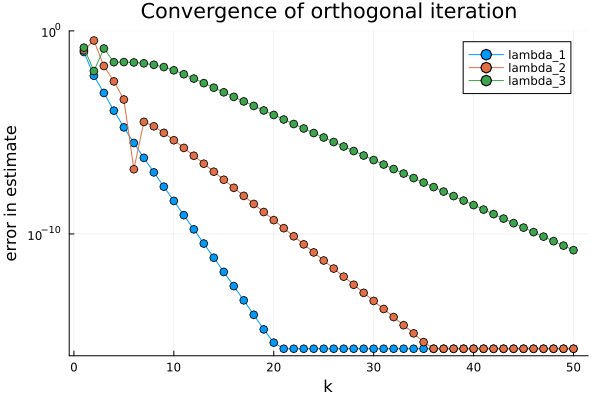

In [7]:
errs = max.(abs.(d .- λ[1:r]), eps())      # floor at machine epsilon so zeros can appear on a log axis
plot(1:numiter,errs',m=:o,label=["lambda_1" "lambda_2" "lambda_3"],
    title="Convergence of orthogonal iteration",
    xlabel="k",yaxis=("error in estimate",:log10,[1e-16,1]))

. . .

All three estimates converge linearly (straight lines on the semilog plot), but at *different* rates. The first eigenvalue is found fastest, and the third slowest. Let's figure out why.

---

### Convergence rate

For $j<n$, the distance between $\operatorname{range}(\mathbf{Q}_k[:,1\!:\!j])$ and $\operatorname{span}\{\mathbf{v}_1,\ldots,\mathbf{v}_j\}$ is $O(\rho_j^k)$, where

$$\rho_j = \left|\frac{\lambda_{j+1}}{\lambda_j}\right|,\qquad j=1,\ldots,n-1.$$

. . .

The $j$th Schur vector $\mathbf{q}_j$ is determined by *both* $\operatorname{range}(\mathbf{Q}_k[:,1\!:\!j])$ and $\operatorname{range}(\mathbf{Q}_k[:,1\!:\!j-1])$. We expect it, and the eigenvalue estimate $(\mathbf{T}_k)_{jj}$, to converge linearly at the rate

$$\max\{\rho_{j-1},\rho_j\}\qquad\text{(with }\rho_0:=0\text{).}$$

. . .


In [8]:
ρ = abs.(λ[2:end] ./ λ[1:end-1])       # ρ_1,…,ρ_{n-1}
@show predicted = [max(j>1 ? ρ[j-1] : 0.0, ρ[j]) for j in 1:r];
@show observed = errs[:,16] ./ errs[:,15];

predicted = [max(if j > 1
            ρ[j - 1]
        else
            0.0
        end, ρ[j]) for j = 1:r] = [0.2, 0.39999999999999997, 0.6]
observed = errs[:, 16] ./ errs[:, 15] = [0.19996702934388394, 0.40119013584238855, 0.5960200605839232]


## QR iteration

What if we want *all* of the Schur decomposition? Take $r=n$ and $\mathbf{Q}_0=\mathbf{I}$ in orthogonal iteration. Then (assuming the leading principal submatrices of $\mathbf{V}^{-1}$ are nonsingular, which is true for a "generic" $\mathbf{A}$) the theorem says that $\mathbf{Q}_k$ converges to the unitary factor of a full Schur decomposition, and

$$\mathbf{T}_k=\mathbf{Q}_k^*\mathbf{A}\mathbf{Q}_k\;\to\;\mathbf{T},\qquad \operatorname{diag}(\mathbf{T})=(\lambda_1,\ldots,\lambda_n).$$

. . .

It turns out that we can organize this computation so that we never form $\mathbf{A}\mathbf{Q}_{k-1}$ at all. We update the matrix $\mathbf{T}_k$ directly.

---

**Algorithm: QR iteration**

Given matrix $\mathbf{A}$:

1. Set $\mathbf{T}_0=\mathbf{A}$.

2. For $k=1,2,\ldots$,

    a. Find a QR factorization $\mathbf{T}_{k-1}=\mathbf{U}_k\mathbf{R}_k$.

    b. Set $\mathbf{T}_k=\mathbf{R}_k\mathbf{U}_k$.

<br><br>

. . .

We factor, then multiply the factors back together *in the reverse order*. Why does this find eigenvalues?

---

::: {.callout-warning icon=false}
## Theorem:
Let $\mathbf{Q}_k=\mathbf{U}_1\mathbf{U}_2\cdots\mathbf{U}_k$. Then

1. $\mathbf{T}_k=\mathbf{U}_k^*\mathbf{T}_{k-1}\mathbf{U}_k=\mathbf{Q}_k^*\mathbf{A}\mathbf{Q}_k$. In particular, $\mathbf{T}_k$ is similar to $\mathbf{A}$.
2. $\mathbf{T}^k=\mathbf{Q}_k\,(\mathbf{R}_k\mathbf{R}_{k-1}\cdots\mathbf{R}_1)$.
:::

<details><summary>Proof:</summary>

For part 1, $\mathbf{U}_k^*\mathbf{T}_{k-1}\mathbf{U}_k=\mathbf{U}_k^*(\mathbf{U}_k\mathbf{R}_k)\mathbf{U}_k=\mathbf{R}_k\mathbf{U}_k=\mathbf{T}_k$, and applying this repeatedly gives $\mathbf{T}_k=\mathbf{Q}_k^*\mathbf{A}\mathbf{Q}_k$.

For part 2, we use induction on $k$. The case $k=1$ is $\mathbf{A}=\mathbf{U}_1\mathbf{R}_1$. If $\mathbf{T}^{k-1}=\mathbf{Q}_{k-1}\mathbf{R}_{k-1}\cdots\mathbf{R}_1$, then by part 1 (in the form $\mathbf{A}\mathbf{Q}_{k-1}=\mathbf{Q}_{k-1}\mathbf{T}_{k-1}$),

$$\mathbf{T}^k=\mathbf{A}\mathbf{Q}_{k-1}\mathbf{R}_{k-1}\cdots\mathbf{R}_1=\mathbf{Q}_{k-1}\mathbf{T}_{k-1}\mathbf{R}_{k-1}\cdots\mathbf{R}_1=\mathbf{Q}_{k-1}\mathbf{U}_k\mathbf{R}_k\mathbf{R}_{k-1}\cdots\mathbf{R}_1=\mathbf{Q}_k\mathbf{R}_k\cdots\mathbf{R}_1.$$
</details>

. . .

Part 2 says that $\mathbf{Q}_k$ is the $\mathbf{Q}$ factor in a QR factorization of $\mathbf{A}^k$. But orthogonal iteration with $r=n$ and $\mathbf{Q}_0=\mathbf{I}$ produces iterates $\tilde{\mathbf{Q}}_k$ with $\mathbf{A}^k=\tilde{\mathbf{Q}}_k\tilde{\mathbf{R}}_k$, from the identity we found earlier. A QR factorization of an invertible matrix is unique up to the signs of the columns of $\mathbf{Q}$ (and rows of $\mathbf{R}$), so $\mathbf{Q}_k=\tilde{\mathbf{Q}}_k$ up to signs.

. . .

**The QR iteration *is* orthogonal iteration in disguise** (with $r=n$ and $\mathbf{Q}_0=\mathbf{I}$), and $\mathbf{A}_k$ is its matrix $\mathbf{T}_k=\mathbf{Q}_k^*\mathbf{A}\mathbf{Q}_k$.

---

Therefore, under the same assumptions as before,

$$\mathbf{A}_k\to\mathbf{T}\text{ (upper triangular)},\qquad \operatorname{diag}(\mathbf{A}_k)\to(\lambda_1,\ldots,\lambda_n),\qquad \mathbf{Q}_k\to\text{Schur vectors (up to signs)}.$$

. . .

The entries below the diagonal decay linearly, with $(\mathbf{A}_k)_{ij}\to0$ at the rate $|\lambda_i/\lambda_j|^k$ for $i>j$. The slowest entries are on the first subdiagonal, with rates $|\lambda_{j+1}/\lambda_j|=\rho_j$.

In [9]:
"""
    qriter(A,numiter)

Perform `numiter` iterations of the QR iteration with the matrix `A`. Returns
the final iterate `A_k`, the accumulated orthogonal matrix `Q_k = U_1⋯U_k`,
and a vector holding the norm of the strictly lower triangular part of `A_k`
after each iteration.
"""
function qriter(A,numiter)
    n = size(A,1)
    Ak = copy(A)
    Q = Matrix(1.0I,n,n)
    below = zeros(numiter)
    for k in 1:numiter
        U,R = qr(Ak)
        U = Matrix(U)
        Ak = R*U                       # factor, then multiply in reverse order
        Q = Q*U
        below[k] = norm(tril(Ak,-1))
    end
    return Ak,Q,below
end

qriter (generic function with 1 method)

. . .

We use a matrix with the same known eigenvalues as before.

In [10]:
λ = [1, 0.2, 0.08, 0.048, 0.0144]
n = length(λ)
V = randn(n,n)
A = V*diagm(λ)/V          # A = V D V⁻¹ has eigenvalues λ

5×5 Matrix{Float64}:
  0.856478   1.46948    3.06393  -0.363371    1.06512
 -0.715294  -1.2143    -2.56708   0.293757   -0.926616
  0.630822   1.07631    2.14148  -0.198485    0.795232
  0.516064   0.752156   1.1158    0.0979942   0.567489
 -0.477454  -0.83339   -1.65593   0.17577    -0.539251

---

After 60 iterations, $\mathbf{A}_k$ looks upper triangular.

In [11]:
Ak,Q,below = qriter(A,60);
round.(Ak,digits=6)

5×5 Matrix{Float64}:
  1.0   0.123432  -2.12288    4.8909     2.58309
 -0.0   0.2       -0.023832  -0.025527   0.332582
  0.0  -0.0        0.08      -0.025419  -0.024581
 -0.0   0.0       -0.0        0.048      0.007617
 -0.0   0.0       -0.0        0.0        0.0144

. . .

The diagonal entries are the eigenvalues, in order of decreasing magnitude, just as predicted:

In [12]:
[diag(Ak) λ]

5×2 Matrix{Float64}:
 1.0     1.0
 0.2     0.2
 0.08    0.08
 0.048   0.048
 0.0144  0.0144

. . .

Since $\mathbf{A}_k$ is similar to $\mathbf{A}$ by the orthogonal matrix $\mathbf{Q}_k=\mathbf{U}_1\cdots\mathbf{U}_k$, we can also check part 1 of the theorem.

In [13]:
@show norm(Q'*A*Q - Ak);

norm(Q' * A * Q - Ak) = 8.720028093431991e-15


---

The part of $\mathbf{A}_k$ below the diagonal decays linearly. The slowest-converging entry is $(\mathbf{A}_k)_{43}$, which has rate $|\lambda_4/\lambda_3|=\rho_3$, the largest of the ratios $\rho_j$.

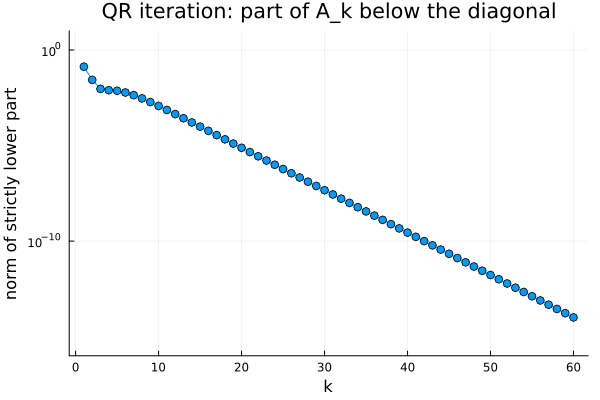

In [14]:
plot(1:60,below,m=:o,title="QR iteration: part of A_k below the diagonal",
    xlabel="k",yaxis=("norm of strictly lower part",:log10,[1e-16,10]),legend=false)

In [15]:
@show observed = below[31]/below[30];
@show theory = maximum(abs.(λ[2:end] ./ λ[1:end-1]));

observed = below[31] / below[30] = 0.6000005489504089
theory = maximum(abs.(λ[2:var"end"] ./ λ[1:var"end" - 1])) = 0.6


---

### Symmetric case

Suppose $\mathbf{A}$ is real and symmetric. Then in a Schur decomposition $\mathbf{A}=\mathbf{Q}\mathbf{T}\mathbf{Q}^\top$,

$$\mathbf{T}^\top=(\mathbf{Q}^\top\mathbf{A}\mathbf{Q})^\top=\mathbf{Q}^\top\mathbf{A}^\top\mathbf{Q}=\mathbf{T}.$$

So $\mathbf{T}$ is both upper triangular and symmetric, and is therefore *diagonal*.

. . .

For a symmetric matrix, **the Schur decomposition and the eigendecomposition are the same**: $\mathbf{T}=\mathbf{D}$, and the Schur vectors are orthonormal eigenvectors. (This is the Spectral Theorem.) For the QR iteration this means that

- every iterate $\mathbf{A}_k=\mathbf{Q}_k^\top\mathbf{A}\mathbf{Q}_k$ is symmetric, and $\mathbf{A}_k$ converges to a *diagonal* matrix holding the eigenvalues;
- the accumulated matrix $\mathbf{Q}_k=\mathbf{U}_1\cdots\mathbf{U}_k$ converges (up to the signs of its columns) to a matrix of orthonormal eigenvectors.

[The eigenvalues converge even faster than for a nonsymmetric matrix. The diagonal entries of a symmetric matrix differ from its eigenvalues only by an amount that is quadratic in the size of the off-diagonal part. So if the off-diagonal part of $\mathbf{A}_k$ is $O(\rho^k)$, then the diagonal entries have error $O(\rho^{2k})$.]{.content-hidden when-format='revealjs' when-format='pptx'}

. . .

We construct a symmetric matrix with the same eigenvalues $\lambda$, using a random orthogonal matrix of eigenvectors.

In [16]:
Q0 = Matrix(qr(randn(n,n)).Q)       # a random orthogonal matrix
S = Q0*diagm(λ)*Q0'
S = (S+S')/2                         # symmetrize, to remove any roundoff asymmetry
Sk,Q,below = qriter(S,60);
round.(Sk,digits=6)

5×5 Matrix{Float64}:
  1.0  -0.0  -0.0   -0.0     0.0
 -0.0   0.2  -0.0   -0.0    -0.0
 -0.0   0.0   0.08   0.0     0.0
  0.0  -0.0   0.0    0.048   0.0
  0.0   0.0  -0.0   -0.0     0.0144

. . .

The iterate is diagonal, and its diagonal agrees with the eigenvalues computed by Julia. Moreover, $\mathbf{Q}_k$ contains the eigenvectors: $\mathbf{S}\mathbf{Q}_k\approx\mathbf{Q}_k\mathbf{D}$.

In [17]:
@show diag(Sk);
@show reverse(eigvals(Symmetric(S)));       # eigvals returns the eigenvalues in ascending order
@show norm(S*Q - Q*Diagonal(diag(Sk)));

diag(Sk) = [0.9999999999999998, 0.19999999999999984, 0.08000000000000006, 0.048, 0.014399999999999987]
reverse(eigvals(Symmetric(S))) = [1.0, 0.20000000000000012, 0.08000000000000003, 0.04800000000000011, 0.014400000000000053]
norm(S * Q - Q * Diagonal(diag(Sk))) = 9.28154267843106e-16


---

### Improvements to QR iteration

The QR iteration as we have described it has two practical drawbacks:

1. **Cost.** Each iteration requires a QR factorization and a matrix product. For a dense $n\times n$ matrix each of these costs $O(n^3)$ flops, and we need many iterations.
2. **Slow convergence.** The linear rate $|\lambda_{j+1}/\lambda_j|$ can be arbitrarily close to $1$. (If $|\lambda_{j+1}|=|\lambda_j|$ for some $j$, the iteration does not converge to a triangular matrix at all.)

. . .

Both can be fixed, and the two fixes together are the basis of the algorithms used in practice. (For example, LAPACK's routines for the nonsymmetric eigenvalue problem, which underlie `eigen` in Julia, are built on them.)

---

#### Reducing the cost: Hessenberg form

A QR factorization is much cheaper for matrices that have some structure. We would like to put $\mathbf{A}$ into such a form *once*, by a similarity transformation (so that the eigenvalues are unchanged), and then keep that structure throughout the iteration.

::: {.callout-note icon=false}
## Definition: Upper Hessenberg matrix
A matrix $\mathbf{H}$ is **upper Hessenberg** if $H_{ij}=0$ whenever $i>j+1$. That is, $\mathbf{H}$ is upper triangular plus one nonzero subdiagonal.
:::

. . .

**Step 1 (done once).** Using $n-2$ Householder reflections, we can compute an orthogonal matrix $\mathbf{P}$ and an upper Hessenberg matrix $\mathbf{H}$ with

$$\mathbf{A}=\mathbf{P}\mathbf{H}\mathbf{P}^\top,$$

at a cost of $O(n^3)$ flops. Since $\mathbf{H}$ is similar to $\mathbf{A}$, it has the same eigenvalues, and a Schur decomposition $\mathbf{H}=\mathbf{Q}\mathbf{T}\mathbf{Q}^\top$ gives one for $\mathbf{A}$ via $\mathbf{A}=(\mathbf{P}\mathbf{Q})\mathbf{T}(\mathbf{P}\mathbf{Q})^\top$.

[We cannot hope to reach triangular form in finitely many steps this way. That would be a finite algorithm for the eigenvalues, and hence for the roots of polynomials of degree $5$ and higher, which cannot exist. Hessenberg form is as far as we can go directly.]{.content-hidden when-format='revealjs' when-format='pptx'}

---

**Step 2 (every iteration).** The QR iteration preserves Hessenberg form: if $\mathbf{H}_{k-1}$ is upper Hessenberg and nonsingular, then so is $\mathbf{H}_k$.

<details><summary>Proof:</summary>

Write $\mathbf{H}_{k-1}=\mathbf{U}_k\mathbf{R}_k$, where $\mathbf{R}_k$ is invertible since $\mathbf{H}_{k-1}$ is. Then $\mathbf{U}_k=\mathbf{H}_{k-1}\mathbf{R}_k^{-1}$ is the product of an upper Hessenberg matrix and an upper triangular matrix, which is upper Hessenberg. Then $\mathbf{H}_k=\mathbf{R}_k\mathbf{U}_k$ is the product of an upper triangular matrix and an upper Hessenberg matrix, which is again upper Hessenberg.
</details>

. . .

And a QR factorization of a Hessenberg matrix is cheap: $\mathbf{U}_k$ can be built from $n-1$ Givens rotations, each eliminating one subdiagonal entry at a cost of $O(n)$. So one QR iteration costs only $O(n^2)$ flops, rather than $O(n^3)$.

. . .

If $\mathbf{A}$ is symmetric, then $\mathbf{H}$ is symmetric and upper Hessenberg, hence *tridiagonal*, and each QR iteration costs only $O(n)$ flops.

---

#### Accelerating convergence: shifts

We met the problem of a slow linear rate before, in the power iteration, and we know a cure: *shift*, and apply the iteration to $(\mathbf{A}-s\mathbf{I})^{-1}$. The analogous modification of QR iteration is the following.

**Algorithm: Shifted QR iteration**

Given matrix $\mathbf{A}$:

1. Set $\mathbf{A}_0=\mathbf{A}$.

2. For $k=1,2,\ldots$,

    a. Choose a shift $s_k$.

    b. Find a QR factorization $\mathbf{A}_{k-1}-s_k\mathbf{I}=\mathbf{U}_k\mathbf{R}_k$.

    c. Set $\mathbf{A}_k=\mathbf{R}_k\mathbf{U}_k+s_k\mathbf{I}$.

<br><br>

. . .

Each step is still a similarity transformation: $\mathbf{A}_k=\mathbf{U}_k^*(\mathbf{A}_{k-1}-s_k\mathbf{I})\mathbf{U}_k+s_k\mathbf{I}=\mathbf{U}_k^*\mathbf{A}_{k-1}\mathbf{U}_k$. So the eigenvalues are preserved, and the Hessenberg structure is too.

---

**Why does this help?** The same argument as for the unshifted algorithm shows $(\mathbf{A}-s_k\mathbf{I})\cdots(\mathbf{A}-s_1\mathbf{I})=\mathbf{Q}_k\mathbf{R}_k\cdots\mathbf{R}_1$, where $\mathbf{Q}_k=\mathbf{U}_1\cdots\mathbf{U}_k$. Solving for $\mathbf{Q}_k$ and looking at its last column (using that $(\mathbf{R}_k\cdots\mathbf{R}_1)^\top$ is lower triangular), we find that, up to scaling,

$$\mathbf{Q}_k\,\mathbf{e}_n\;\propto\;(\mathbf{A}^\top-s_k\mathbf{I})^{-1}\cdots(\mathbf{A}^\top-s_1\mathbf{I})^{-1}\mathbf{e}_n.$$

. . .

That is, the last column of $\mathbf{Q}_k$ is generated by **inverse iteration** with shifts $s_1,\ldots,s_k$ (applied to $\mathbf{A}^\top$, which has the same eigenvalues as $\mathbf{A}$). With a shift close to $\lambda_n$, the last row of $\mathbf{A}_k$ converges very fast.

. . .

Just as in the dynamic shifting of inverse iteration, the best choice is to use our best current eigenvalue estimate as the shift: $s_k=(\mathbf{A}_{k-1})_{nn}$, the *Rayleigh quotient shift*. Typically, this gives *quadratic* convergence of the last row of $\mathbf{A}_k$ to $\begin{bmatrix}0&\cdots&0&\lambda_n\end{bmatrix}$.

---

Once the entry $(\mathbf{A}_k)_{n,n-1}$ is negligible, we have found $\lambda_n\approx(\mathbf{A}_k)_{nn}$. We then **deflate**: the matrix has the block form

$$\mathbf{A}_k=\begin{bmatrix}\mathbf{B} & \mathbf{c}\\ \mathbf{0} & \lambda_n\end{bmatrix},$$

whose remaining eigenvalues are those of the smaller $(n-1)\times(n-1)$ matrix $\mathbf{B}$, and we continue on $\mathbf{B}$ alone.

. . .

In practice, one uses more robust shifts (such as the Wilkinson shift, from the trailing $2\times2$ block) and an implicit version of shifted QR iteration that handles complex eigenvalues of real matrices in real arithmetic. Combined with Hessenberg reduction and deflation, this typically needs only a small number of iterations per eigenvalue, and finds all of the eigenvalues of a dense matrix in $O(n^3)$ flops in total.

. . .

These methods are the workhorses for dense matrices of moderate size. For large sparse matrices, we will want methods that use only matrix-vector products, which is the subject of the next lectures.

<!--
[verbose test]{.content-hidden when-format="revealjs" when-format="pptx"}

::: {.callout-caution icon=false}
## Exercise: 

:::

<details><summary>Answer:</summary> </details>


::: {.callout-note icon=false}
## Definition: 
 
:::


::: {.callout-tip icon=false}
## Note: 
 
:::
-->